# What Drives Developer Pay? An Analysis of the 2024 Stack Overflow Developer Survey

This notebook follows the **CRISP-DM** process. Each section is also labelled with the matching step of the data science process:

| CRISP-DM phase | Data science step(s) | Section |
|---|---|---|
| Business Understanding | Define questions | 1 |
| Data Understanding | **Gather**, **Assess** | 2, 3 |
| Data Preparation | **Clean** | 4 |
| (Descriptive answers to Q1 to Q3) | **Analyze**, **Visualize** | 5 |
| Modeling | **Model** | 6 |
| Evaluation | **Evaluate**, **Visualize** | 7 |
| Deployment | Predict a new scenario | 8 |

## 1. Business Understanding

Developer salaries vary enormously around the world. Anyone planning a tech career (students, job switchers, or people negotiating a raise) wants to know which factors actually move pay.

**Questions of interest**

1. **Experience:** How much does salary grow with years of professional coding?
2. **Remote work:** Do remote developers earn more than hybrid or in-person developers?
3. **Location:** How much does the country you live in affect your pay?
4. **Prediction:** Can we predict whether a developer earns **above the median salary** from a few facts about them, and which facts matter most?

Questions 1 to 3 are answered with **descriptive statistics** (medians, counts) and charts. Question 4 needs **machine learning**: it is a yes/no (classification) problem, evaluated with accuracy, precision, recall and related scores.

In [1]:
# Libraries used in this project
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Project-wide settings (constants are written in UPPER_CASE, as PEP8 suggests)
RANDOM_STATE = 42                      # makes results repeatable
DATA_PATH = 'data/survey_results_public.zip'   # zipped CSV; pandas reads it directly
SCHEMA_PATH = 'data/survey_results_schema.csv'
IMAGE_DIR = 'images'                   # charts for the blog post are saved here
NUMERIC_FEATURES = ['YearsCodePro']
CATEGORICAL_FEATURES = ['Country', 'EdLevel', 'RemoteWork', 'OrgSize', 'DevType', 'Age']
TARGET_SALARY = 'ConvertedCompYearly'

os.makedirs(IMAGE_DIR, exist_ok=True)
sns.set_theme(style='whitegrid')

## 2. Gather

The data is the public 2024 Stack Overflow Developer Survey (65,437 responses, 114 columns), downloaded from Stack Overflow's survey site. Two files are used:

* `survey_results_public.zip`: one row per respondent, one column per answer. The original CSV is 160 MB, so it is stored zipped (17 MB) to fit GitHub's upload limit; pandas reads the zip file directly.
* `survey_results_schema.csv`: the full question text behind each column name.

In [2]:
def load_data(data_path, schema_path):
    """Load the survey answers and the question descriptions.

    Args:
        data_path (str): path to the survey results CSV file.
        schema_path (str): path to the schema CSV file.

    Returns:
        tuple: (survey DataFrame, schema DataFrame)
    """
    survey = pd.read_csv(data_path, low_memory=False)
    schema = pd.read_csv(schema_path)
    return survey, schema


survey_df, schema_df = load_data(DATA_PATH, SCHEMA_PATH)
print('Rows, columns:', survey_df.shape)
survey_df.head(3)

Rows, columns: (65437, 114)


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN


## 3. Assess

In [3]:
def describe_columns(schema, columns):
    """Print the survey question behind each column name.

    Args:
        schema (DataFrame): the survey schema (qname and question columns).
        columns (list): column names to describe.
    """
    for col in columns:
        question = schema.loc[schema['qname'] == col, 'question']
        text = (question.iloc[0][:110] if len(question)
                else '(added by Stack Overflow: salary converted to US dollars)')
        print(f'{col:22s} -> {text}')


def missing_report(df, columns):
    """Return the percentage of missing values per column, largest first.

    Args:
        df (DataFrame): data to check.
        columns (list): columns to include in the report.

    Returns:
        DataFrame: one row per column with its % of missing values.
    """
    missing = df[columns].isna().mean().sort_values(ascending=False) * 100
    return missing.round(2).to_frame('% missing')


COLUMNS_OF_INTEREST = ['MainBranch', 'Employment'] + NUMERIC_FEATURES \
    + CATEGORICAL_FEATURES + [TARGET_SALARY]
describe_columns(schema_df, COLUMNS_OF_INTEREST)

MainBranch             -> Which of the following options best describes you today? For the purpose of this survey, a developer is "someo
Employment             -> Which of the following best describes your current employment status? Select all that apply.*
YearsCodePro           -> NOT including education, how many years have you coded professionally (as a part of your work)?
Country                -> Where do you live? <span style="font-weight: bolder;">*</span>
EdLevel                -> Which of the following best describes the highest level of formal education that you’ve completed? *
RemoteWork             -> Which best describes your current work situation?
OrgSize                -> Approximately how many people are employed by the company or organization you currently work for?  This should
DevType                -> Which of the following describes your current job, the one you do most of the time? Please select only one.
Age                    -> What is your age?*
ConvertedComp

`ConvertedCompYearly` is the salary each person entered, converted by Stack Overflow into **US dollars per year**. This makes salaries comparable across countries, so it is our main measure of pay.

In [4]:
# How much data is missing in each column of interest (whole survey)?
missing_report(survey_df, COLUMNS_OF_INTEREST)

,% missing
ConvertedCompYearly,64.19
OrgSize,27.44
YearsCodePro,21.13
RemoteWork,16.25
Country,9.94
DevType,9.16
EdLevel,7.11
MainBranch,0.00
Employment,0.00
Age,0.00


**Observation:** about 64% of respondents did not report a salary. Students, hobbyists and people who skipped the question all fall in this group. Other columns are missing for 7% to 27% of people, mostly because many questions were only shown to people with a job.

count        23,435
mean         86,155
std         186,757
min               1
25%          32,712
50%          65,000
75%         107,972
max      16,256,603
Name: ConvertedCompYearly, dtype: str
Skewness: 52.9


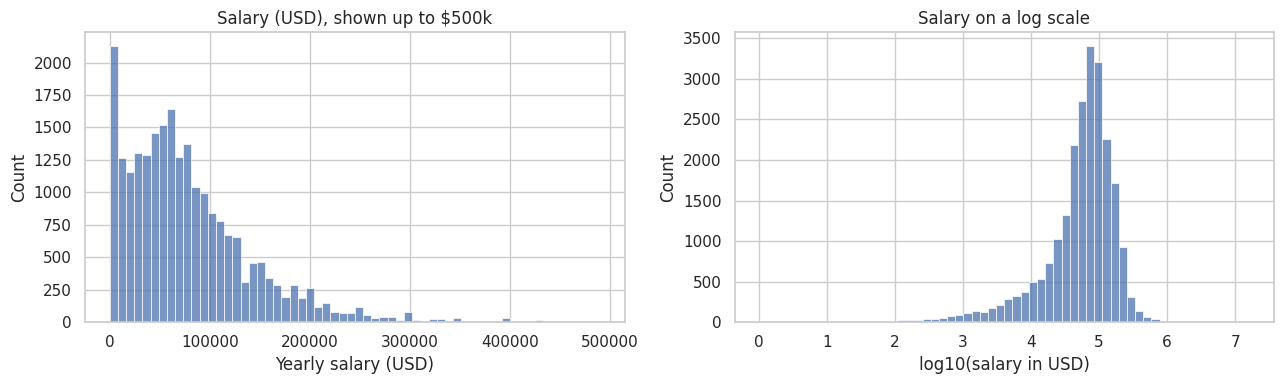

In [5]:
# Distribution of salary: is it skewed?
salary = survey_df[TARGET_SALARY].dropna()
print(salary.describe().apply(lambda value: f'{value:,.0f}'))
print('Skewness:', round(salary.skew(), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(salary[salary < 500_000], bins=60, ax=axes[0])
axes[0].set_title('Salary (USD), shown up to $500k')
axes[0].set_xlabel('Yearly salary (USD)')
sns.histplot(np.log10(salary), bins=60, ax=axes[1])
axes[1].set_title('Salary on a log scale')
axes[1].set_xlabel('log10(salary in USD)')
plt.tight_layout()
plt.show()

**Observation:** salary is **heavily right-skewed** (skewness of about 53). Most people earn between about \$30k and \$110k, but a few report tens of millions, and some report \$1. On a log scale the distribution looks much closer to a bell curve. Because of this skew, **medians** (not means) are used to summarise pay throughout the notebook, since a median is not pulled up by a few extreme values.

In [6]:
# Years of professional experience is stored as text; look at its unusual values
print(survey_df['YearsCodePro'].dropna().unique()[:15])
print(survey_df['YearsCodePro'].value_counts().loc[['Less than 1 year', 'More than 50 years']])

<StringArray>
[              '17',               '27',                '7',
               '11',               '25',               '12',
               '10',                '3', 'Less than 1 year',
               '18',               '37',               '15',
               '20',                '6',                '2']
Length: 15, dtype: str
YearsCodePro
Less than 1 year      2856
More than 50 years      50
Name: count, dtype: int64


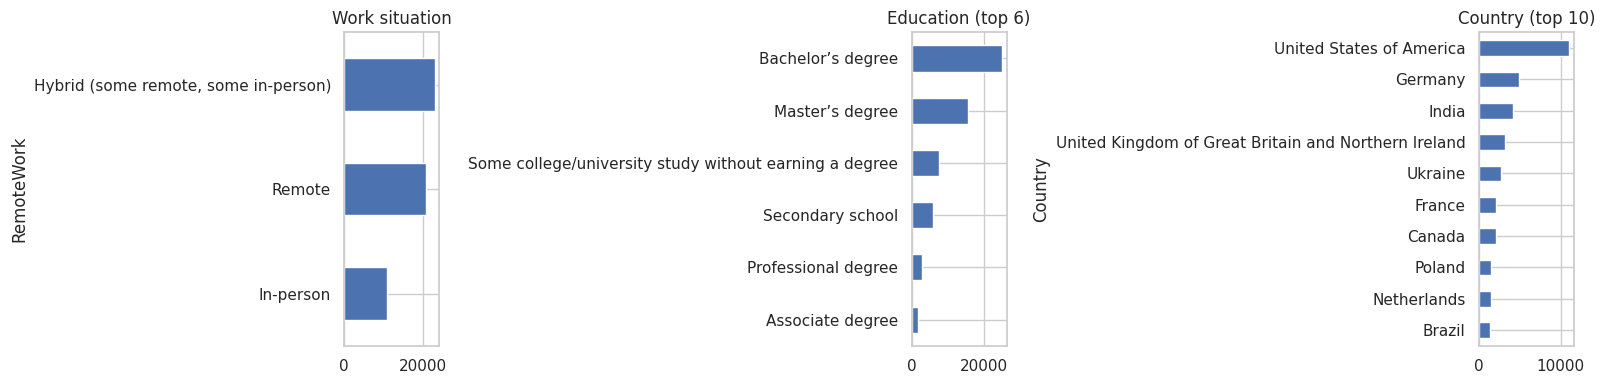

Distinct countries: 185 | Distinct job types: 34


In [7]:
# Distribution of the main categorical answers
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
survey_df['RemoteWork'].value_counts().plot.barh(ax=axes[0], title='Work situation')
education_counts = survey_df['EdLevel'].value_counts().head(6)
education_counts.index = [label.split(' (')[0] for label in education_counts.index]
education_counts.plot.barh(ax=axes[1], title='Education (top 6)')
survey_df['Country'].value_counts().head(10).plot.barh(ax=axes[2], title='Country (top 10)')
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()
print('Distinct countries:', survey_df['Country'].nunique(),
      '| Distinct job types:', survey_df['DevType'].nunique())

### Summary of assessment: does the data need cleaning?

**Yes.** The assessment found five problems:

1. **Missing salaries** (about 64% of rows).
2. **Extreme salary outliers** (from \$1 up to \$16 million).
3. **Mixed respondents**: students, hobbyists and part-timers sit alongside full-time professionals.
4. **Experience stored as text** ("Less than 1 year", "More than 50 years").
5. **Categories with many rare values** (185 countries, about 35 job types) and some blank answers.

The next section fixes each problem and explains **why** each approach was chosen.

## 4. Clean

### How missing values are handled, and why

| Column(s) | Approach | Why this approach |
|---|---|---|
| `ConvertedCompYearly` (salary, the target) | **Drop rows** | Salary is the thing we study and predict. Filling it in (for example with the average) would invent salaries and teach the model made-up answers. |
| `YearsCodePro` (experience) | **Drop rows** | After the other filters, under 0.3% of rows are missing it, so dropping them loses almost nothing. Filling with the median would wrongly treat unknown people as "typical", for the most important numeric feature. |
| `EdLevel`, `RemoteWork`, `OrgSize`, `DevType`, `Age` | **Fill with "Unknown"** | Each is missing for 0.15% of rows or fewer after filtering. Keeping these rows with an "Unknown" category keeps their useful information, and avoids guessing an answer the person never gave. "Unknown" becomes its own category, so the model can learn if skipping a question means anything. |

The same cleaned data is used for **both** the descriptive answers (Q1 to Q3) and the model (Q4), so every result is based on the same group of people. For the remote-work question, the few "Unknown" rows are left out of the chart, because "Unknown" is not a work arrangement.

### How categorical values are handled, and why

* **Rare categories are grouped into "Other"**: only the 20 largest countries and 12 most common job types are kept by name. Categories with a handful of people give unreliable medians, and they would add many near-empty columns to the model, which encourages overfitting.
* **One-hot encoding** (in Section 6): each category becomes its own 0/1 column. This suits these variables because they have **no natural order** (Germany is not "more than" India). Assigning numbers such as 1, 2, 3 would wrongly suggest an order.

### Other cleaning steps

* **Keep only full-time professional developers**, so we compare like with like.
* **Remove unrealistic salaries**: under \$1,000 a year (almost certainly typos or monthly amounts) and the top 1% (extreme outliers).
* **Convert experience to numbers**: "Less than 1 year" becomes 0.5 and "More than 50 years" becomes 51.

In [8]:
def filter_professionals(df):
    """Keep only professional developers who are employed full-time.

    Args:
        df (DataFrame): raw survey data.

    Returns:
        DataFrame: filtered copy of the data.
    """
    is_professional = df['MainBranch'] == 'I am a developer by profession'
    is_full_time = df['Employment'] == 'Employed, full-time'
    return df[is_professional & is_full_time].copy()


def remove_salary_outliers(df, column, min_salary=1_000, upper_quantile=0.99):
    """Drop rows with no salary or an unrealistic salary.

    Args:
        df (DataFrame): data containing the salary column.
        column (str): name of the salary column.
        min_salary (float): lowest salary kept, in US dollars per year.
        upper_quantile (float): salaries above this quantile are dropped.

    Returns:
        DataFrame: data with missing and extreme salaries removed.
    """
    df = df.dropna(subset=[column])
    max_salary = df[column].quantile(upper_quantile)
    print(f'Salary range kept: ${min_salary:,.0f} to ${max_salary:,.0f}')
    return df[df[column].between(min_salary, max_salary)]


def years_to_number(value):
    """Convert a 'years of experience' survey answer into a number.

    Args:
        value (str or NaN): answer such as '5', 'Less than 1 year'
            or 'More than 50 years'.

    Returns:
        float: number of years, or NaN if the answer is missing.
    """
    if pd.isna(value):
        return np.nan
    if value == 'Less than 1 year':
        return 0.5
    if value == 'More than 50 years':
        return 51.0
    return float(value)


def group_rare_categories(series, top_n, other_label='Other'):
    """Keep the top_n most common categories and label the rest as 'Other'.

    Args:
        series (Series): categorical column.
        top_n (int): number of categories to keep by name.
        other_label (str): label given to all remaining categories.

    Returns:
        Series: column with rare categories grouped together.
    """
    top_values = series.value_counts().head(top_n).index
    return series.where(series.isin(top_values), other_label)


def clean_data(df):
    """Run every cleaning step and return data ready for analysis.

    Args:
        df (DataFrame): raw survey data.

    Returns:
        DataFrame: cleaned data with numeric experience, grouped
            categories and no missing values in the analysis columns.
    """
    data = filter_professionals(df)
    data = remove_salary_outliers(data, TARGET_SALARY)

    data['YearsCodePro'] = data['YearsCodePro'].apply(years_to_number)
    print('Rows missing experience (dropped):', data['YearsCodePro'].isna().sum())
    data = data.dropna(subset=['YearsCodePro'])

    data['Country'] = group_rare_categories(data['Country'], top_n=20)
    data['DevType'] = group_rare_categories(data['DevType'], top_n=12)
    for col in ['EdLevel', 'RemoteWork', 'OrgSize', 'DevType', 'Age']:
        data[col] = data[col].fillna('Unknown')

    data['Country'] = data['Country'].replace({
        'United States of America': 'USA',
        'United Kingdom of Great Britain and Northern Ireland': 'UK',
        'Russian Federation': 'Russia'})
    return data


clean_df = clean_data(survey_df)
print('Rows after cleaning:', len(clean_df))

Salary range kept: $1,000 to $400,000


Rows missing experience (dropped): 42
Rows after cleaning: 15787


In [9]:
# Check: no missing values remain in the columns used for analysis
missing_report(clean_df, NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET_SALARY])

,% missing
YearsCodePro,0.0
Country,0.0
EdLevel,0.0
RemoteWork,0.0
OrgSize,0.0
DevType,0.0
Age,0.0
ConvertedCompYearly,0.0


After cleaning, almost 16,000 full-time professional developers remain, a large sample with no missing values in the analysis columns.

## 5. Analyze and Visualize (Questions 1 to 3)

These questions do not need machine learning: **descriptive statistics** (the median salary and the number of people in each group) answer them directly. Two small helper functions avoid repeating the same code for every question.

In [10]:
def median_salary_by(df, column, salary_col=TARGET_SALARY):
    """Calculate the median salary and group size for each value of a column.

    Args:
        df (DataFrame): cleaned data.
        column (str): column to group by.
        salary_col (str): salary column to summarise.

    Returns:
        DataFrame: 'median' and 'count' per group.
    """
    return (df.groupby(column, observed=True)[salary_col]
              .agg(['median', 'count']).round(0))


def plot_median_bar(values, title, color, filename, xlabel='', horizontal=False):
    """Draw a bar chart of median salaries and save it to the images folder.

    Args:
        values (Series): median salary per group (index = group labels).
        title (str): chart title.
        color (str): bar colour.
        filename (str): file name for the saved PNG.
        xlabel (str): label for the group axis (vertical charts only).
        horizontal (bool): draw horizontal bars (good for long lists).
    """
    if horizontal:
        fig, ax = plt.subplots(figsize=(9, 7))
        sns.barplot(x=values.values, y=list(values.index), color=color, ax=ax)
        ax.set_xlabel('Median salary (USD)')
        ax.set_ylabel('')
    else:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        sns.barplot(x=list(values.index), y=values.values, color=color, ax=ax)
        for i, value in enumerate(values.values):
            ax.text(i, value + 1500, f'${value / 1000:.0f}k',
                    ha='center', fontweight='bold')
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Median salary (USD)')
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGE_DIR, filename), dpi=150)
    plt.show()

### Question 1: How much does salary grow with experience?

                  median  count
ExperienceBand                 
0-2 yrs          35936.0   1992
3-5 yrs          50915.0   3573
6-10 yrs         73924.0   4538
11-20 yrs        90886.0   3830
20+ yrs         109039.0   1854


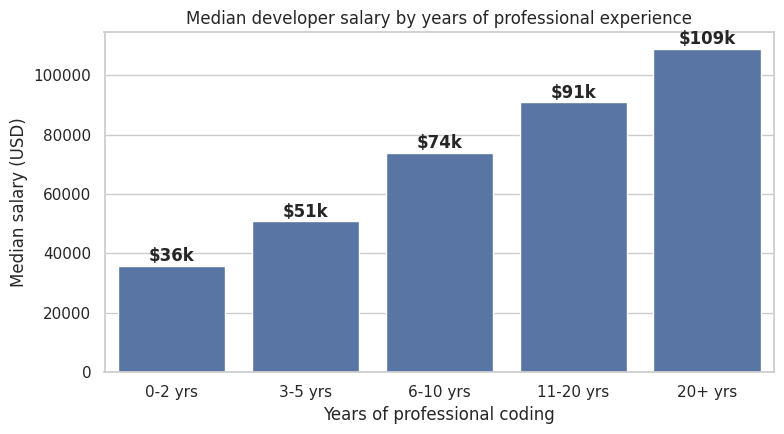

In [11]:
experience_bins = [0, 2, 5, 10, 20, 60]
experience_labels = ['0-2 yrs', '3-5 yrs', '6-10 yrs', '11-20 yrs', '20+ yrs']
clean_df['ExperienceBand'] = pd.cut(clean_df['YearsCodePro'], bins=experience_bins,
                                    labels=experience_labels, include_lowest=True)

experience_table = median_salary_by(clean_df, 'ExperienceBand')
print(experience_table)
plot_median_bar(experience_table['median'],
                'Median developer salary by years of professional experience',
                '#4C72B0', 'q1_experience.png', xlabel='Years of professional coding')

**Finding:** pay rises steadily with experience. The median developer with 0 to 2 years earns about **\$36k**, which roughly **doubles by 6 to 10 years (\$74k)** and **triples after 20 years (\$109k)**. The biggest jumps come in the first decade.

### Question 2: Do remote developers earn more?

                                       median  count
RemoteWork                                          
Hybrid (some remote, some in-person)  71239.0   7002
In-person                             48333.0   2759
Remote                                81528.0   6024

Median salary within the same country:
RemoteWork  Hybrid (some remote, some in-person)  In-person    Remote
Country                                                              
Germany                                  75292.0    59073.0   82703.0
India                                    25123.0    10380.0   23927.0
USA                                     140000.0   112000.0  155000.0


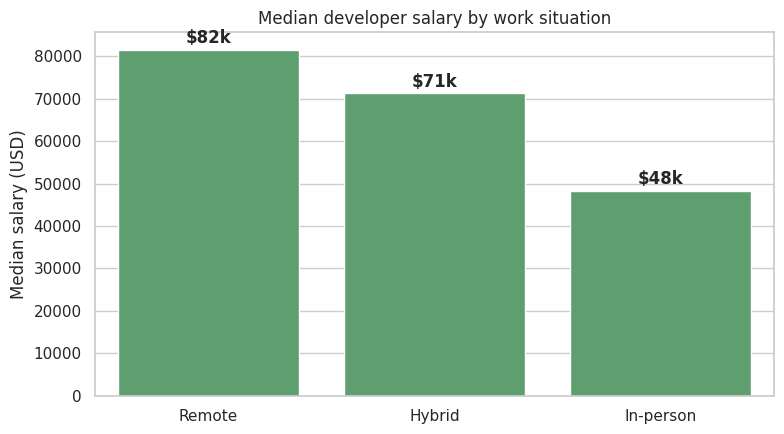

In [12]:
known_remote = clean_df[clean_df['RemoteWork'] != 'Unknown']
remote_table = median_salary_by(known_remote, 'RemoteWork')
print(remote_table)

# Remote workers may simply live in richer countries, so also compare
# within the same country.
within_country = (known_remote[known_remote['Country'].isin(['USA', 'Germany', 'India'])]
                  .groupby(['Country', 'RemoteWork'])[TARGET_SALARY].median()
                  .unstack().round(0))
print('\nMedian salary within the same country:')
print(within_country)

remote_order = ['Remote', 'Hybrid (some remote, some in-person)', 'In-person']
remote_medians = remote_table.loc[remote_order, 'median']
remote_medians.index = ['Remote', 'Hybrid', 'In-person']
plot_median_bar(remote_medians, 'Median developer salary by work situation',
                '#55A868', 'q2_remote.png')

**Finding:** remote developers report the highest median pay (**\$82k**), ahead of hybrid (\$71k) and in-person (\$48k). Part of this gap exists because remote workers are more common in high-paying countries. However, the gap holds **within the same country** for the USA (remote \$155k vs in-person \$112k) and Germany (\$83k vs \$59k). In India, remote and hybrid are similar, and both are well above in-person.

*Caution:* this shows that remote work and higher pay go together, not that going remote **causes** a raise. Remote roles may simply be more common at better-paying companies or among more senior staff.

### Question 3: How much does location matter?

                  median  count
Country                        
USA             149000.0   3490
Israel          119810.0    171
Switzerland     116988.0    249
Australia        95796.0    353
Canada           87231.0    639
UK               84076.0   1037
Norway           80722.0    186
Germany          75184.0   1327
Netherlands      70244.0    383
Austria          69814.0    186
Sweden           57230.0    346
Poland           54442.0    294
France           53703.0    667
Czech Republic   48600.0    146
Spain            48333.0    389
Italy            41351.0    381
Ukraine          35545.0    811
Russia           29132.0    170
Brazil           25777.0    421
India            17945.0    787


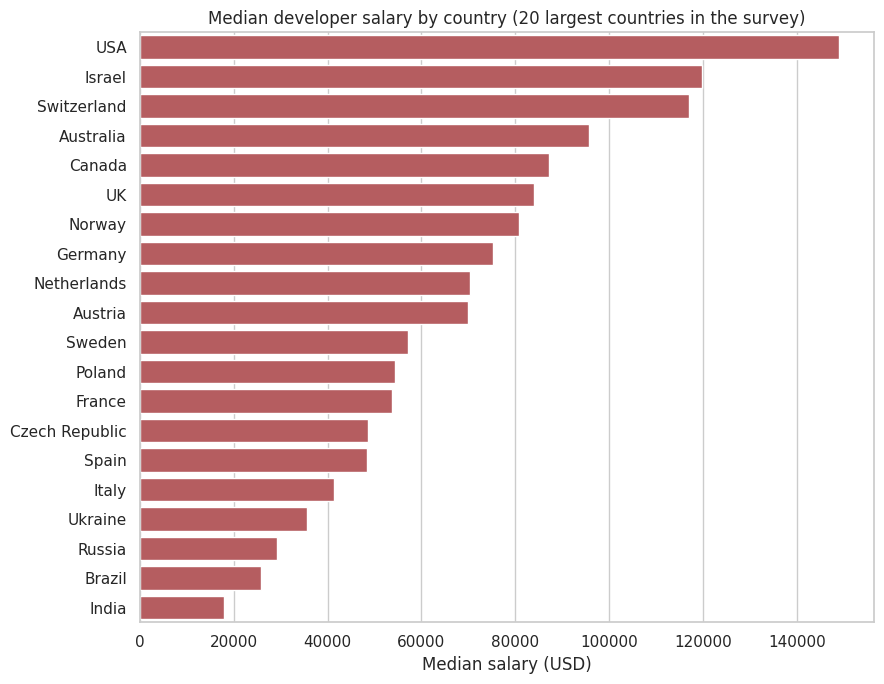

In [13]:
country_table = (median_salary_by(clean_df[clean_df['Country'] != 'Other'], 'Country')
                 .sort_values('median', ascending=False))
print(country_table)
plot_median_bar(country_table['median'],
                'Median developer salary by country (20 largest countries in the survey)',
                '#C44E52', 'q3_country.png', horizontal=True)

**Finding:** location has the biggest effect of anything studied. A typical developer in the **USA (\$149k)** earns about **8 times** as much as one in **India (\$18k)**, and roughly double the median in Germany (\$75k). These figures are not adjusted for cost of living.

## 6. Model (Question 4)

### Creating the prediction target

Salary is turned into a yes/no label: **does this developer earn more than the median salary of the cleaned group?** Splitting at the median gives two equally sized classes, so a model that guesses randomly would score about 50% accuracy. That is our baseline to beat.

In [14]:
median_salary = clean_df[TARGET_SALARY].median()
clean_df['HighEarner'] = (clean_df[TARGET_SALARY] > median_salary).astype(int)
print(f'Median salary: ${median_salary:,.0f}')
print(clean_df['HighEarner'].value_counts(normalize=True).round(3))

X = clean_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = clean_df['HighEarner']

# Hold back 20% of developers that the model never sees during training.
# 'stratify' keeps the 50/50 balance in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Median salary: $70,393
HighEarner
0    0.5
1    0.5
Name: proportion, dtype: float64
Training rows: 12629 | Test rows: 3158


### Preparing the features inside a pipeline

* **Categorical columns** are **one-hot encoded**: each category becomes a 0/1 column. `handle_unknown='ignore'` means a category never seen in training does not crash the model.
* **Experience** (the numeric column) is **standardised** (rescaled to mean 0, spread 1) so that Logistic Regression treats it on a similar scale to the 0/1 columns.

Both steps sit inside a scikit-learn `Pipeline`. The preparation is learned from the training data only, then applied identically to the test data and to any new developer we predict for. This prevents information from the test set leaking into training.

Two models are compared:

* **Logistic Regression**: a simple, easy-to-explain model that adds up the effect of each factor.
* **Random Forest**: many decision trees voting together; it can capture interactions (for example, experience mattering more in some countries).

In [15]:
def build_pipeline(model):
    """Wrap a scikit-learn model with the feature preparation steps.

    Args:
        model (estimator): an unfitted scikit-learn classifier.

    Returns:
        Pipeline: one-hot encoding + scaling followed by the model.
    """
    preprocess = ColumnTransformer([
        ('num', StandardScaler(), NUMERIC_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_FEATURES)])
    return Pipeline([('prep', preprocess), ('model', model)])


models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=RANDOM_STATE, n_jobs=-1)}

pipelines = {}
for name, model in models.items():
    pipelines[name] = build_pipeline(model).fit(X_train, y_train)
    print(f'Trained: {name}')

Trained: Logistic Regression


Trained: Random Forest


## 7. Evaluate and Visualize

In [16]:
def evaluate_model(pipeline, X_eval, y_eval):
    """Score a fitted model on held-out data.

    Args:
        pipeline (Pipeline): fitted model pipeline.
        X_eval (DataFrame): features of the evaluation set.
        y_eval (Series): true labels of the evaluation set.

    Returns:
        dict: accuracy, precision, recall, F1 and ROC AUC.
    """
    predictions = pipeline.predict(X_eval)
    probabilities = pipeline.predict_proba(X_eval)[:, 1]
    return {'Accuracy': accuracy_score(y_eval, predictions),
            'Precision': precision_score(y_eval, predictions),
            'Recall': recall_score(y_eval, predictions),
            'F1': f1_score(y_eval, predictions),
            'ROC AUC': roc_auc_score(y_eval, probabilities)}


results = pd.DataFrame({name: evaluate_model(pipe, X_test, y_test)
                        for name, pipe in pipelines.items()}).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.828,0.846,0.802,0.823,0.903
Random Forest,0.820,0.843,0.787,0.814,0.903


Best model by F1 score: Logistic Regression 

                    precision    recall  f1-score   support

At or below median       0.81      0.85      0.83      1579
      Above median       0.85      0.80      0.82      1579

          accuracy                           0.83      3158
         macro avg       0.83      0.83      0.83      3158
      weighted avg       0.83      0.83      0.83      3158



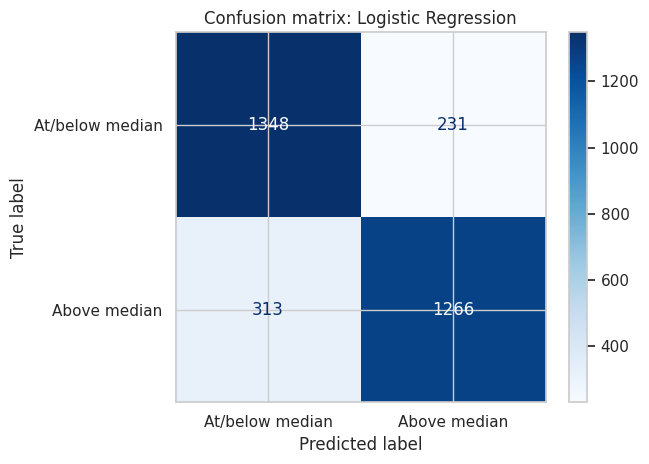

In [17]:
best_name = results['F1'].idxmax()
best_model = pipelines[best_name]
print('Best model by F1 score:', best_name, '\n')
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=['At or below median', 'Above median']))

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test,
                                      display_labels=['At/below median', 'Above median'],
                                      cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
plt.tight_layout()
plt.show()

### What the scores mean

* **Accuracy**: the share of all developers the model labelled correctly. Random guessing would get about 0.50.
* **Precision**: of the developers the model *said* are high earners, how many really are? High precision means few false alarms.
* **Recall**: of the developers who *really are* high earners, how many did the model find? High recall means few high earners are missed.
* **F1**: a single score that balances precision and recall.
* **ROC AUC**: how well the model ranks people. If you pick one high earner and one low earner at random, it is the chance the model gives the high earner the higher score (0.5 = coin flip, 1.0 = perfect).
* **Confusion matrix**: the raw counts behind these scores: correct answers on the diagonal, mistakes off it.

Both models score far above the 50% baseline (about 83% accuracy, ROC AUC about 0.90), which shows that a handful of facts about a developer carries a lot of information about their pay. Precision is a little higher than recall, so the model is slightly cautious: it misses some high earners rather than raising false alarms. The remaining errors make sense, because the survey does not capture skill level, negotiation, the specific employer, or the city someone lives in.

Country         0.281
YearsCodePro    0.090
Age             0.013
OrgSize         0.010
DevType         0.007
RemoteWork      0.007
EdLevel         0.005
dtype: float64


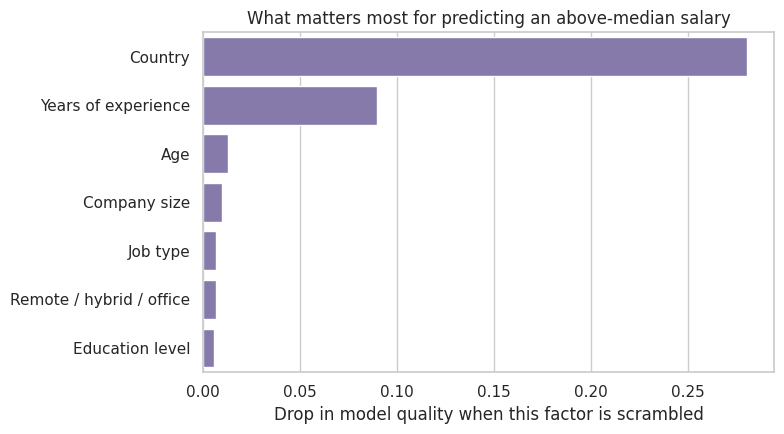

In [18]:
# Which factors does the model rely on most?
# Permutation importance: shuffle one column at a time and measure how much
# the model's ROC AUC drops. A bigger drop means a more important factor.
importance_result = permutation_importance(best_model, X_test, y_test, n_repeats=5,
                                           random_state=RANDOM_STATE, scoring='roc_auc',
                                           n_jobs=-1)
importance = (pd.Series(importance_result.importances_mean, index=X_test.columns)
                .sort_values(ascending=False))
print(importance.round(3))

readable_names = {'Country': 'Country', 'YearsCodePro': 'Years of experience',
                  'DevType': 'Job type', 'RemoteWork': 'Remote / hybrid / office',
                  'OrgSize': 'Company size', 'Age': 'Age', 'EdLevel': 'Education level'}
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=importance.values, y=[readable_names[i] for i in importance.index],
            color='#8172B2', ax=ax)
ax.set_title('What matters most for predicting an above-median salary')
ax.set_xlabel('Drop in model quality when this factor is scrambled')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, 'q4_importance.png'), dpi=150)
plt.show()

**Finding:** **country** is by far the most important factor, followed by **years of experience**. Education level matters least once the other facts are known.

## 8. Deployment: a new scenario

**Scenario:** *Sara* is a back-end developer in **Germany** with **4 years** of professional experience and a bachelor's degree. She works **in-person** at a company with 100 to 499 employees and is 25 to 34 years old. She is wondering which step would do more for her pay: **asking to go remote**, or **staying put and building experience**.

We ask both models for her chance of earning above the survey median today, and under each option.

In [19]:
def predict_scenarios(fitted_pipelines, scenarios):
    """Predict the chance of above-median pay for imagined developers.

    Args:
        fitted_pipelines (dict): model name -> fitted pipeline.
        scenarios (dict): scenario name -> dict of feature values.

    Returns:
        DataFrame: one row per scenario, one probability column per model.
    """
    scenario_df = pd.DataFrame(scenarios.values(), index=scenarios.keys())
    scenario_df = scenario_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    return pd.DataFrame({name: pipe.predict_proba(scenario_df)[:, 1]
                         for name, pipe in fitted_pipelines.items()},
                        index=scenario_df.index)


sara = {'YearsCodePro': 4, 'Country': 'Germany',
        'EdLevel': 'Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
        'RemoteWork': 'In-person', 'OrgSize': '100 to 499 employees',
        'DevType': 'Developer, back-end', 'Age': '25-34 years old'}

sara_scenarios = {
    'Sara today (in-person, 4 years)': sara,
    'Sara goes remote': {**sara, 'RemoteWork': 'Remote'},
    'Sara in 4 more years (in-person, 8 years)': {**sara, 'YearsCodePro': 8},
    'Sara in 4 more years AND remote': {**sara, 'YearsCodePro': 8, 'RemoteWork': 'Remote'},
}
predict_scenarios(pipelines, sara_scenarios).style.format('{:.0%}')

,Logistic Regression,Random Forest
"Sara today (in-person, 4 years)",34%,22%
Sara goes remote,56%,45%
"Sara in 4 more years (in-person, 8 years)",48%,48%
Sara in 4 more years AND remote,69%,68%


**What the prediction tells a reader:** today, the best model (Logistic Regression) gives Sara about a **34%** chance of earning above the survey median (\$70k). Comparing her options:

* **Going remote** raises her chance to about **56%**.
* **Four more years of experience**, staying in-person, raises it to about **48%**.
* **Doing both** raises it to about **69%**.

The Random Forest gives slightly different numbers (22%, 45%, 48% and 68%) but tells the same story, which makes the conclusion more trustworthy.

So for a developer like Sara, the model suggests that work arrangement is linked to a pay difference at least as large as several years of experience. Remember the caution from Question 2: the model learned that remote developers *tend* to earn more, not that switching to remote guarantees a raise. A better reading is: *"remote back-end roles in Germany tend to be better paid, so they are worth looking at."*

## Conclusion

1. **Experience:** median pay roughly triples from the first two years (\$36k) to 20+ years (\$109k).
2. **Remote work:** remote developers earn the most (\$82k median), and the gap remains within the USA and Germany.
3. **Location:** country is the strongest single factor; US developers earn about 8 times what Indian developers do (in US dollars).
4. **Prediction:** with just seven facts about a developer, a Logistic Regression model predicts above- or below-median pay with **83% accuracy** (ROC AUC 0.90), compared with 50% for random guessing. Country and experience drive most of its decisions.

**Limitations:** salaries are self-reported and not adjusted for cost of living. Survey respondents are not a perfect random sample of all developers. The model finds patterns (correlations), not causes.